# 02 — Building localization results

The model (U-Net with a ResNet-34 encoder) learns to find buildings in the **pre-disaster** image.
Training runs from the terminal, not in this notebook, because it takes a few hours:

```bash
cd ~/Desktop/fyp
/opt/anaconda3/bin/python3 -m src.train --epochs 30
```

Running the same command again resumes from the last finished epoch.
This notebook reads what training saved in `runs/loc_resnet34/` and shows the results. You can run it while training is still going.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from src.dataset import BuildingDataset
from src.train import build_model, pick_device

RUN_DIR = PROJECT_ROOT / "runs" / "loc_resnet34"
DATA_ROOT = PROJECT_ROOT / "data" / "processed"

## Training curves

,epoch,train_loss,f1,precision,recall,lr,minutes
25,26,0.319825,0.791700,0.827293,0.759044,1.296818e-05,6.691803
26,27,0.317377,0.791781,0.818464,0.766783,7.341523e-06,6.694144
27,28,0.312108,0.778371,0.845610,0.721037,3.277860e-06,6.683499
28,29,0.317987,0.784275,0.840045,0.735449,8.217157e-07,6.694186
29,30,0.318133,0.785786,0.837020,0.740462,0.000000e+00,6.699242


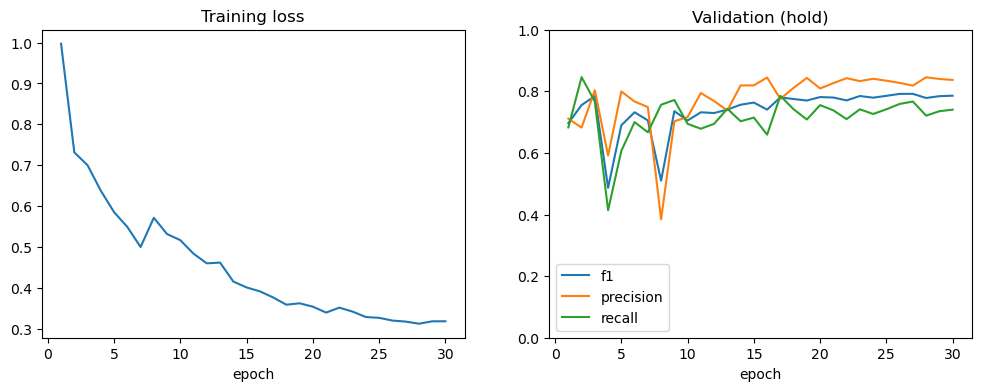

In [2]:
history = pd.read_csv(RUN_DIR / "history.csv")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history.epoch, history.train_loss)
ax1.set(title="Training loss", xlabel="epoch")
for col in ["f1", "precision", "recall"]:
    ax2.plot(history.epoch, history[col], label=col)
ax2.set(title="Validation (hold)", xlabel="epoch", ylim=(0, 1))
ax2.legend()
fig.savefig(RUN_DIR / "curves.png", dpi=150, bbox_inches="tight")
history.tail()

## Predictions on validation tiles

Left: pre-disaster image. Middle: true buildings. Right: what the model found.

best checkpoint: epoch 27, F1 0.7918


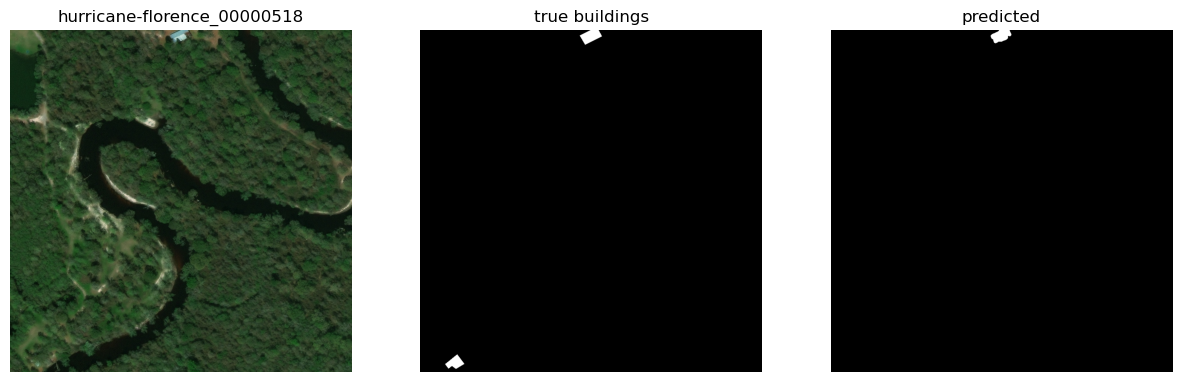

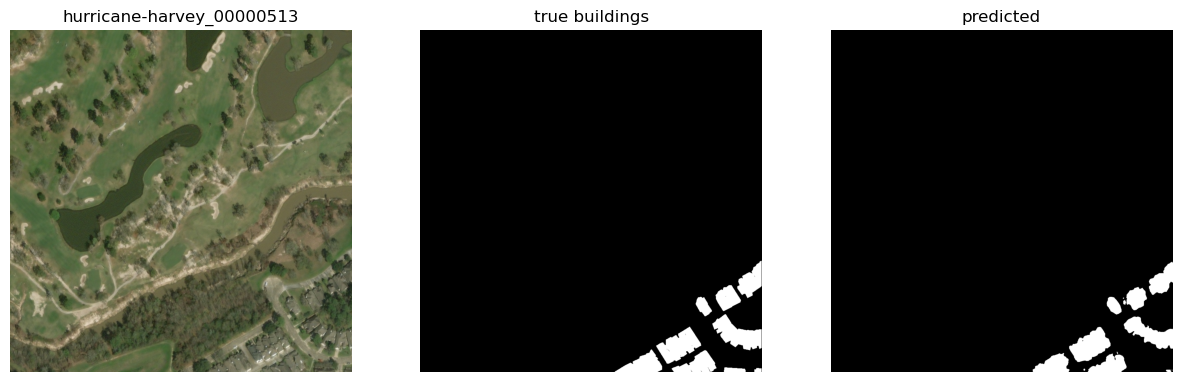

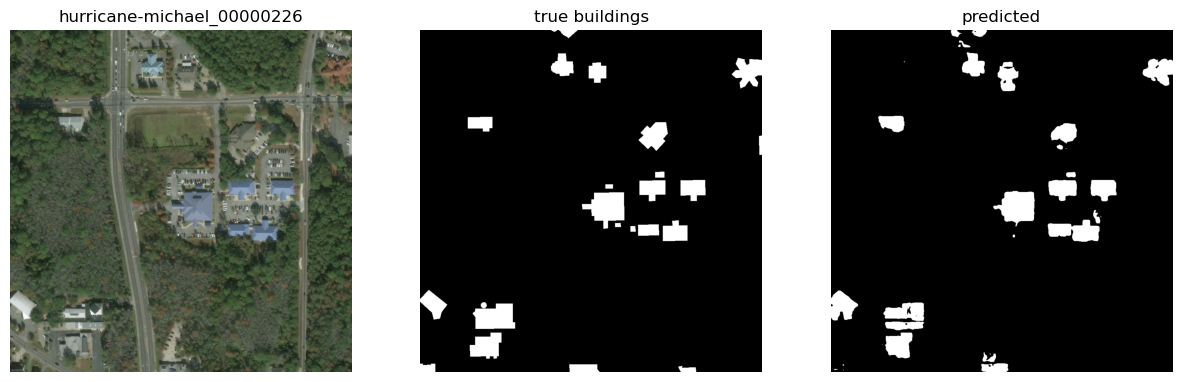

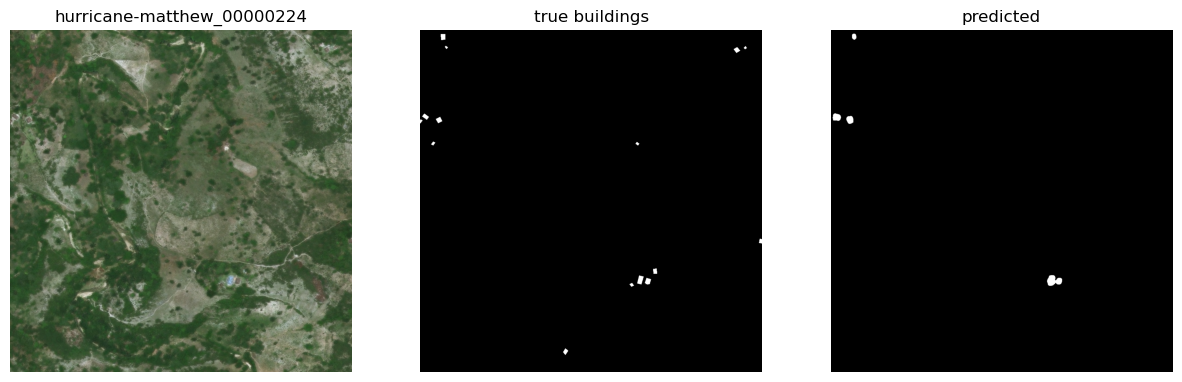

In [3]:
device = pick_device()
model = build_model(pretrained=False).to(device)
best = torch.load(RUN_DIR / "best.pt", map_location=device)
model.load_state_dict(best["model"])
model.eval()
print(f"best checkpoint: epoch {best['epoch'] + 1}, F1 {best['f1']:.4f}")

val_ds = BuildingDataset([DATA_ROOT / "hold"], crop=None, augment=False)
hurricane_idx = [i for i, p in enumerate(val_ds.mask_paths) if p.stem.startswith("hurricane")]
rng = np.random.default_rng(0)

for i in rng.choice(hurricane_idx, 4, replace=False):
    image, mask = val_ds[i]
    with torch.no_grad():
        pred = torch.sigmoid(model(image[None].to(device)))[0, 0].cpu().numpy() > 0.5
    rgb = (image.numpy().transpose(1, 2, 0) * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406]).clip(0, 1)
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for ax, img, title in zip(axes, [rgb, mask[0], pred], [val_ds.mask_paths[i].stem, "true buildings", "predicted"]):
        ax.imshow(img, cmap=None if img.ndim == 3 else "gray")
        ax.set_title(title)
        ax.axis("off")
    plt.show()

## Results to record

- Best validation F1: ___ (epoch ___)
- Precision / recall: ___ / ___
- What the model misses (small buildings? buildings under trees?): ___

For reference, the top xView2 challenge entries reached a localization F1 of roughly 0.86 using much larger models and ensembles. Anything above 0.75 is a solid baseline for this project.